In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Step 2: Load the Dataset

In [7]:
df = pd.read_csv("Wine.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nColumns:")
print(df.columns)

First 5 rows:
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065                 1  
1 

Step 3: Separate Features and Target

In [8]:
# Last column is considered the target/class column

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

Step 4: Standardize the Features

In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nStandardized Data:")
print(X_scaled[:5])



Standardized Data:
[[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]


Step 5: Apply PCA

In [12]:
# Reduce all features to 2 principal components

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("\nTransformed Data using PCA:")
print(X_pca[:5])


Transformed Data using PCA:
[[ 3.31675081  1.44346263]
 [ 2.20946492 -0.33339289]
 [ 2.51674015  1.0311513 ]
 [ 3.75706561  2.75637191]
 [ 1.00890849  0.86983082]]


Step 6: Explained Variance

In [14]:
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance captured by 2 PCs:",
      pca.explained_variance_ratio_.sum())


Explained Variance Ratio:
[0.36198848 0.1920749 ]

Total Variance captured by 2 PCs: 0.5540633835693527


Step 7: Create DataFrame of PCA Results and Visualize


PCA DataFrame:
   Principal Component 1  Principal Component 2  Target
0               3.316751               1.443463       1
1               2.209465              -0.333393       1
2               2.516740               1.031151       1
3               3.757066               2.756372       1
4               1.008908               0.869831       1


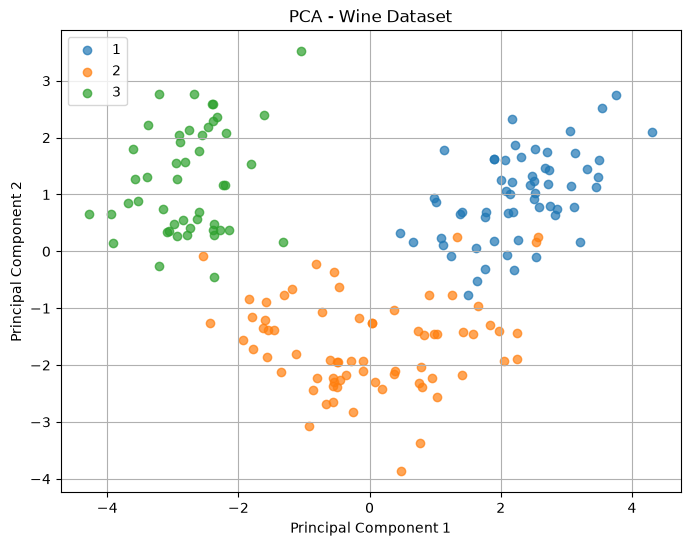

In [15]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["Target"] = y.values

print("\nPCA DataFrame:")
print(pca_df.head())

plt.figure(figsize=(8, 6))

# Get unique classes
classes = y.unique()

for cls in classes:
    data = pca_df[pca_df["Target"] == cls]

    plt.scatter(
        data["Principal Component 1"],
        data["Principal Component 2"],
        label=str(cls),
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()